In [312]:
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
import colorcet as cc
import toolz as tz
import copy
import re
import os

from tqdm.auto import tqdm
from glob import glob

from sklearn.metrics import confusion_matrix, balanced_accuracy_score, accuracy_score
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.preprocessing import StandardScaler

plt.rcParams["scatter.edgecolors"] = "none"
plt.rcParams["savefig.bbox"] = 'tight'
plt.rcParams["axes.labelsize"] = 16
np.set_printoptions(legacy="1.21",linewidth=150)

import torch

device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

Using cpu device


# Limpieza de datos

Dejamos sólo las features y los géneros que indica el enunciado.

Simplificamos los nombres de las clases.

Traducimos los géneros a una clase numérica como requiere torch para usar el cross entropy loss.

Dejamos las features `X` y los labels `y` en tensores para usar el DataLoader de torch.

In [70]:
genres = ["dance","jazz","reggae","punk","metal"]
translation = dict(map(reversed,enumerate(genres)))
translation

{'dance': 0, 'jazz': 1, 'reggae': 2, 'punk': 3, 'metal': 4}

In [71]:
%%time 
expr_genre_simplify_names = pl.col("genre").str.replace_many({" and electronica": ""," and blues": "","soul and ": ""})
expr_genre_passlist = pl.col("genre").is_in(genres)
expr_genre_to_int = pl.col("genre").replace_strict(translation)

data = (
  pl.scan_csv("genre_dataset.txt",skip_rows=9,quote_char=None)
  .drop("track_id","title","artist_name")
  .rename({"%genre": "genre"})
  .with_columns(expr_genre_simplify_names)
  .filter(expr_genre_passlist)
  .with_columns(expr_genre_to_int)
  .collect()
)

CPU times: user 337 ms, sys: 159 ms, total: 496 ms
Wall time: 276 ms


In [72]:
data.sample(10)

genre,loudness,tempo,time_signature,key,mode,duration,avg_timbre1,avg_timbre2,avg_timbre3,avg_timbre4,avg_timbre5,avg_timbre6,avg_timbre7,avg_timbre8,avg_timbre9,avg_timbre10,avg_timbre11,avg_timbre12,var_timbre1,var_timbre2,var_timbre3,var_timbre4,var_timbre5,var_timbre6,var_timbre7,var_timbre8,var_timbre9,var_timbre10,var_timbre11,var_timbre12
i64,f64,f64,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2,-7.089,145.157,1,5,1,253.72689,47.391467,19.362724,5.023316,-12.942363,21.740331,-18.328743,6.464599,-0.25842,-7.114973,-4.387695,-0.925884,14.011018,17.879122,2147.438329,1699.256695,767.284345,981.690226,409.730292,953.867441,323.794761,471.066023,217.751389,148.304636,389.008335
0,-18.432,45.345,1,9,0,244.84526,35.859045,-216.550715,49.482209,2.311773,-9.87178,-27.27548,19.596748,8.640444,-14.203824,-5.913425,4.636238,-2.121296,22.755861,2739.054485,981.992069,663.218415,1005.284282,246.052219,576.219277,314.98531,619.587654,127.08737,84.987118,323.798153
3,-8.994,101.662,4,2,1,206.39302,45.020515,66.35187,10.129888,2.61345,-41.27547,-5.122093,-16.267006,-3.820882,14.539583,7.318278,-1.427762,8.574492,38.0247,1552.864116,3524.887222,2869.43917,738.722033,1625.357164,383.373826,724.159433,405.50476,424.340529,352.510362,168.762655
0,-15.887,119.61,4,5,1,244.45342,34.992422,-133.897352,5.835423,-11.765623,1.168678,-24.691088,-0.667005,0.992843,6.99224,-3.427032,1.205485,-4.766305,59.548229,4415.838511,1898.028274,1911.914684,1019.885176,476.881241,758.862634,602.22411,682.62994,273.888611,266.357182,458.776862
0,-9.86,131.619,4,10,0,337.91955,44.062109,3.79397,19.761437,5.806764,-29.959874,-3.096984,2.510157,2.075636,0.228646,3.094958,-0.842421,8.879688,27.151776,2090.594807,1502.848108,1485.415043,879.106287,1013.098103,414.863829,385.437839,375.198452,334.479366,267.624487,202.481643
1,-13.921,87.851,3,3,1,284.52526,38.611344,-34.467681,49.344442,5.709152,2.422606,0.235238,-8.798506,-2.053702,6.794456,4.181606,-0.318258,2.133974,39.286708,2551.871711,4979.605344,2518.987072,978.853286,1698.211531,674.588419,524.950435,364.845363,275.286562,403.372055,364.378127
3,-11.443,156.843,4,2,1,241.76281,41.189659,23.809139,-38.436657,-12.145334,16.054313,-20.86672,1.304074,-11.279537,6.530736,7.238214,-0.752011,-2.87493,37.130963,1765.336008,2131.304262,1818.610155,779.823891,959.917975,633.353743,435.839131,283.492957,254.926163,346.55838,291.074846
1,-21.464,229.367,3,11,1,361.1424,28.429513,-77.313711,-29.475849,-7.59878,28.419431,-21.347021,3.65933,-1.593426,1.870536,5.982599,-1.664629,-8.129444,51.272712,3286.385875,2032.672682,1259.846785,819.850984,906.243517,561.405312,423.344902,286.416686,313.547962,151.578997,292.15865
0,-5.592,191.178,3,9,0,306.93832,43.533938,40.359728,13.242326,55.102421,45.891369,6.136555,-7.997067,7.393715,0.757818,10.342836,5.513206,12.030079,50.674499,8104.21902,5044.061481,3940.983298,2715.607607,2588.234202,1856.650661,1490.235162,646.611946,677.864131,749.399727,694.512209


In [73]:
X = torch.tensor(data.drop("genre").to_numpy(),dtype=torch.float32)
y = torch.tensor(data["genre"].to_numpy())

Separamos en entrenamiento (60%), validación (20%) y prueba (20%).

Los autores no entienden por qué no existe esta función en las librerías estándar de ML.

In [74]:
def split_thrice(*collections,train_size=0.7,test_size=np.nan,val_size=np.nan,**kwargs):
    """Like sklearn train_test_split but for three categories. kwargs are passed to the sklearn function.
    If two of the sizes are NaN, the other two are assumed equal. If all sizes are None, all are assumed equal.
    The return style is different from sklearn. Tuples with the train, test and validation samples are returned separately."""
    sizes = np.array([train_size,test_size,val_size])
    nan_count = np.isnan(sizes).sum()
    rest = 1-np.nansum(sizes)
    sizes[np.isnan(sizes)] = rest / nan_count
    train_size,test_size,val_size = sizes
    p = train_size
    q = test_size / (1-p)
    first_split = train_test_split(*collections,train_size=p,**kwargs)
    train, other = zip(*tz.partition(2,first_split))
    second_split = train_test_split(*other,train_size=q,**kwargs)
    test, val = zip(*tz.partition(2,second_split))
    return list(train), list(test), list(val)

In [75]:
train, test, val = split_thrice(X,y,train_size=0.7,val_size=0.15,shuffle=True)

Quisiéramos verificar que la distribución de clases es igual en entrenamiento, prueba y validación:

Text(0, 0.5, 'Fracción')

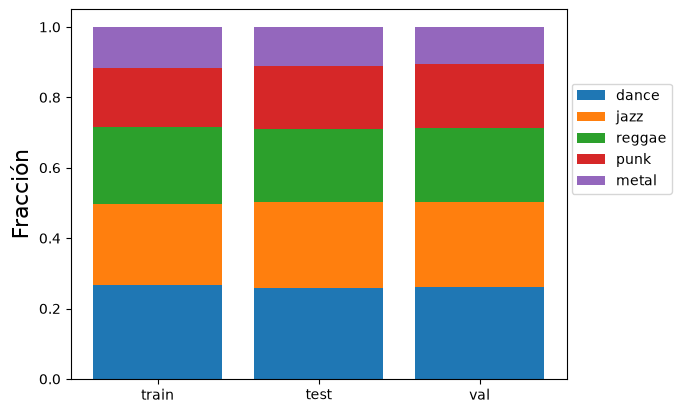

In [76]:
for name,y_ in {"train":train[1],"test":test[1],"val":val[1]}.items():
    xs = np.histogram(y_.cpu(),bins=np.arange(6)-0.5)[0]
    xs = xs/xs.sum()
    bottom = 0
    for i,x_ in enumerate(xs):
        plt.bar(name,x_,bottom=bottom,color=f"C{i}",label=(genres[i] if name=="train" else None))
        bottom += x_
plt.legend(loc=[1.01,0.5])
plt.ylabel("Fracción")

## Escalado

Entrenamos un StandardScaler con los datos de entrenamiento únicamente para evitar data leak.

In [77]:
scaler = StandardScaler().fit(train[0])
for S in [train,test,val]:
    S[0] = torch.tensor(scaler.transform(S[0]),dtype=torch.float32)

## Exporte

Exportamos estos datos divididos y escalados para hacer la búsqueda de grilla de hiperparámetros con los mismos datos (sino estaríamos haciendo data leaking)

In [79]:
for name,struct in {"train":train,"test":test,"val":val}.items():
    fname = f"./grid_search/data/{name}.npz"
    if os.path.exists(fname):
        tmp = np.load(fname)
        struct[0] = torch.tensor(tmp["X"],dtype=torch.float32)
        struct[1] = torch.tensor(tmp["y"])
    else:
        np.savez(fname,X=struct[0].numpy(),y=struct[1].numpy(),allow_pickle=False)

# Definición del modelo

Creamos una fábrica de perceptrones multicapa para explorar distintas arquitecturas

In [80]:
def make_mlp(input_size:int,output_size:int,hidden_layers=[20,20,20]):
    sizes = [input_size, *hidden_layers, output_size]
    layers = [torch.nn.Linear(a,b,bias=True) for (a,b) in tz.sliding_window(2,sizes)]
    n = len(layers)
    activations = [torch.nn.ReLU() for _ in range(n-1)]
    return torch.nn.Sequential(*tz.interleave([layers,activations]))

# prefiero hacer esto que hacer una subclase
def make_dataloader(X,y,batch_size):
    return torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(X,y),
        batch_size=batch_size,
        shuffle=True
    )

# Estrategia de entrenamiento

Usaremos Adam para entrenar el modelo, y probamos con los siguientes parámetros que parecen plausibles para una red pequeña.

Revisaremos a detalle este entrenamiento para ver qué se puede hacer masivamente y cóm ose decidirá la condición de parada.

In [212]:
model = make_mlp(
    input_size = X.shape[1],
    output_size = len(y.unique()),
    hidden_layers = [20]*3
)
model.to(device)
loss_fn = torch.nn.CrossEntropyLoss()

learning_rate = 8e-3#7.943e-03#3e-3
batch_size = 400
epochs = 70
L2_lambda = 3e-4


train_loader = make_dataloader(*train,batch_size=batch_size)
test_loader = make_dataloader(*test,batch_size=batch_size)
val_loader = make_dataloader(*val,batch_size=len(val[1]))

optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=L2_lambda, fused=True)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, "min", patience=5, factor=0.5,threshold=0.01)

In [213]:
measures = {
    "train_loss":np.zeros(epochs),
    "val_loss":np.zeros(epochs),
    "lr":np.zeros(epochs),
    "val_acc":np.zeros(epochs)
}

for epoch in tqdm(range(epochs),desc="Epoch"):
    model.train()
    this_epoch_train_losses = []
    for X,y in train_loader:
        pred = model(X)
        loss = loss_fn(pred, y)
        train_loss = loss.item()
        this_epoch_train_losses.append(train_loss)
        loss.backward()
        optimizer.step()
        optimizer.zero_grad(set_to_none=True) # los gradientes son acumulativos por defecto
    model.eval()
    with torch.no_grad(): # por diseño evaluamos todos los datos de validación en un solo batch
        for X,y in val_loader: # aquí sólo hay una iteración
            pred = model(X)
            val_loss = loss_fn(pred, y).item()
            val_acc = balanced_accuracy_score(y.cpu(),pred.argmax(axis=1).cpu())

    scheduler.step(val_loss)
    lr = scheduler.get_last_lr()[0]
    #print(f"{train_loss = :.3f}     {val_loss = :.3f}     {val_acc = :.3f}    {lr = :.0e}")
    measures["train_loss"][epoch] = np.mean(this_epoch_train_losses)
    measures["val_loss"][epoch] = val_loss
    measures["lr"][epoch] = lr
    measures["val_acc"][epoch] = val_acc

Epoch:   0%|          | 0/70 [00:00<?, ?it/s]

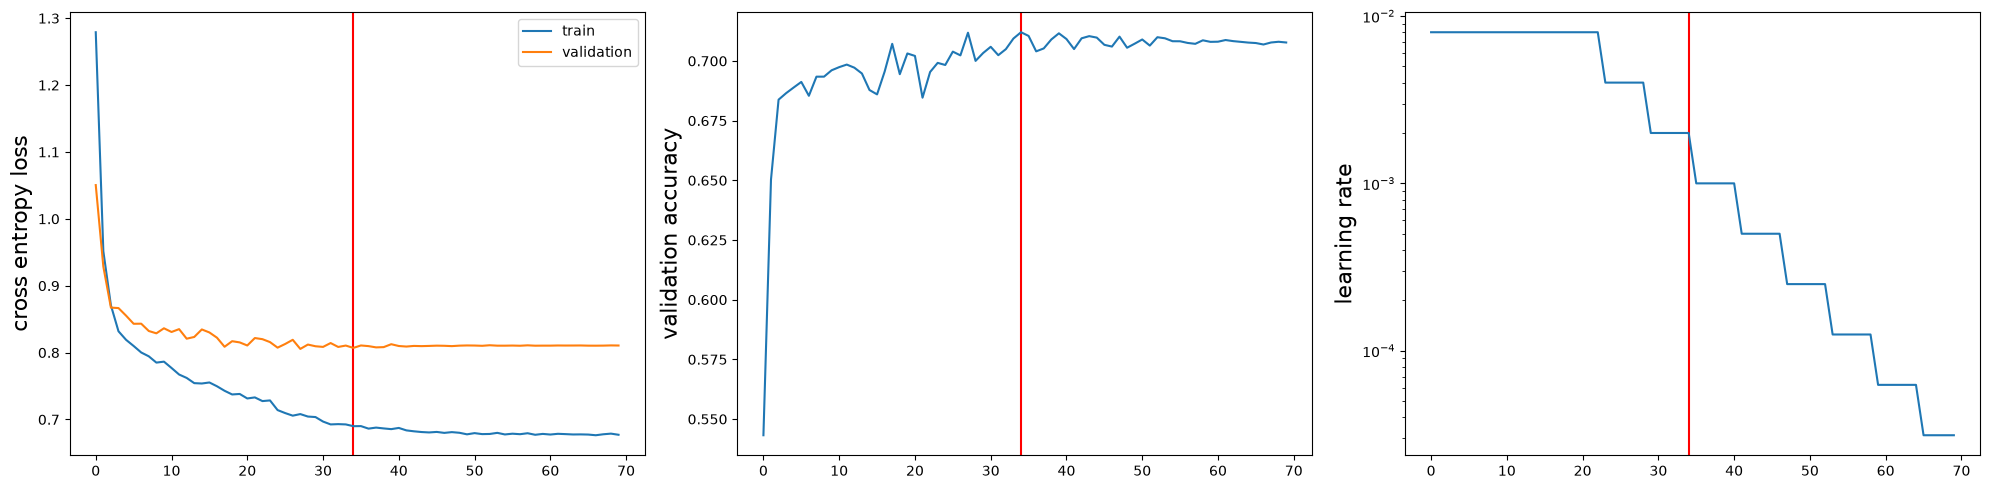

In [214]:
e = measures['val_acc'].argmax()
fig,ax = plt.subplots(1,3,figsize=(20,5))
plt.sca(ax[0]); plt.ylabel("cross entropy loss")
plt.axvline(e,c='r',zorder=-1)
plt.plot(measures["train_loss"],label="train")
plt.plot(measures["val_loss"],label="validation")
plt.legend(loc=0)
plt.sca(ax[1]); plt.ylabel("validation accuracy")
plt.axvline(e,c='r',zorder=-1)
plt.plot(measures['val_acc'])
plt.sca(ax[2]); plt.ylabel("learning rate")
plt.axvline(e,c='r',zorder=-1)
plt.plot(measures["lr"])
plt.yscale("log")
plt.tight_layout()

In [215]:
measures['val_loss'].argmin()

27

In [216]:
measures['val_acc'].max()

0.7120299554053628

In [217]:
measures['val_acc'].argmax()

34

In [218]:
y_pred = model(test[0]).argmax(axis=1).numpy()
y_test = test[1].numpy()

In [81]:
def title(y_true,y_pred,name=""):
    cm = confusion_matrix(y_true,y_pred, normalize="pred")
    tr = np.trace(cm)
    cn = np.linalg.cond(cm)
    bacc = balanced_accuracy_score(y_true,y_pred)
    return f"{name}\ntrace = {tr:.4g}\ncondition number = {cn:.4g}\nbalanced accuracy = {100*bacc:.2f}%"

[Text(0.5, 1.0, '4 layers of 30 neurons\ntrace = 3.624\ncondition number = 1.815\nbalanced accuracy = 71.37%')]

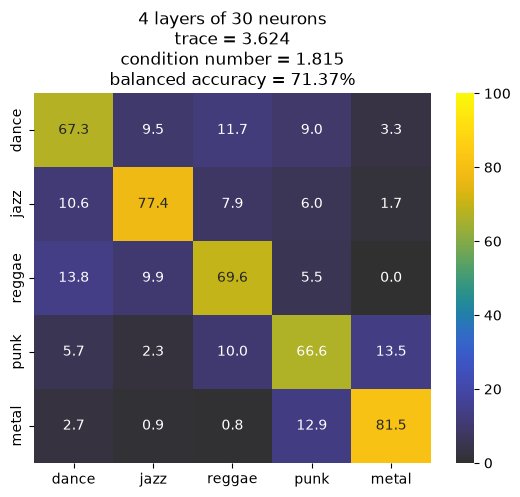

In [220]:
CM = confusion_matrix(y_test,y_pred,normalize="pred")
kwargs = dict(xticklabels=genres,yticklabels=genres,annot=True,fmt='.1f',vmin=0,vmax=100,cmap=cc.cm.gouldian)
report = title(y_test,y_pred,name="4 layers of 30 neurons")
sns.heatmap(100*CM,**kwargs).set(title=report)

# Parada de entrenamiento basada en paciencia

Entrenaremos el modelo hasta un númeor máximo de épocas, llevando cuenta de la mejor accuracy. Dado un número de épcoas de paciencia, si durante el entrenamiento el validation accuracy no mejora respecto al último máximo, pararemos de entrenar y recuperaremos los parámetros del modelo con mejor accuracy.

In [243]:
def train_mlp_classifier(train_Xy,val_Xy,hidden_layers=[20]*3,acc_tol=1e-2,patience=15,
                         learning_rate=1e-3,batch_size=200,max_epochs=100,L2_lambda=1e-4,progress=True):
    n_in = val_Xy[0].shape[1]
    n_out = len(np.unique(train_Xy[1]))
    train_loader = make_dataloader(*train_Xy,batch_size=batch_size)
    val_loader = make_dataloader(*val_Xy,batch_size=len(val[1]))

    model = make_mlp(n_in,n_out,hidden_layers)
    model.to(device)
    loss_fn = torch.nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=L2_lambda, fused=True)
    #scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, "min", patience=3, factor=0.5,threshold=0.01)

    best_acc = -np.inf
    best_state = None
    no_improv = 0

    for epoch in tqdm(range(epochs),desc="Epoch",disable=not progress):
        # Train section
        model.train()
        for X,y in train_loader:
            pred = model(X)
            loss = loss_fn(pred,y)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad(set_to_none=True)
        # validate section
        model.eval()
        with torch.no_grad():
            for X,y in val_loader:
                y_pred = model(X).argmax(axis=1)
                val_acc = balanced_accuracy_score(y.cpu(),y_pred.cpu())
        # check section
        if val_acc > best_acc + acc_tol:
            best_acc = val_acc
            no_improv = 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            no_improv += 1
        if no_improv > patience:
            break
        # learning rate sceduler
        #scheduler.step(val_loss)
    # either way
    print(epoch)
    model.load_state_dict(best_state)
    return model, best_acc

In [244]:
%time train_mlp_classifier(train,val,hidden_layers=[30]*3,batch_size=700,learning_rate=5e-3)

Epoch:   0%|          | 0/70 [00:00<?, ?it/s]

23
CPU times: user 3min 4s, sys: 408 ms, total: 3min 5s
Wall time: 22.1 s


(Sequential(
   (0): Linear(in_features=30, out_features=30, bias=True)
   (1): ReLU()
   (2): Linear(in_features=30, out_features=30, bias=True)
   (3): ReLU()
   (4): Linear(in_features=30, out_features=30, bias=True)
   (5): ReLU()
   (6): Linear(in_features=30, out_features=5, bias=True)
 ),
 0.6932740587808576)

[Text(0.5, 1.0, '3 layers of 30 neurons\ntrace = 3.624\ncondition number = 1.815\nbalanced accuracy = 71.37%')]

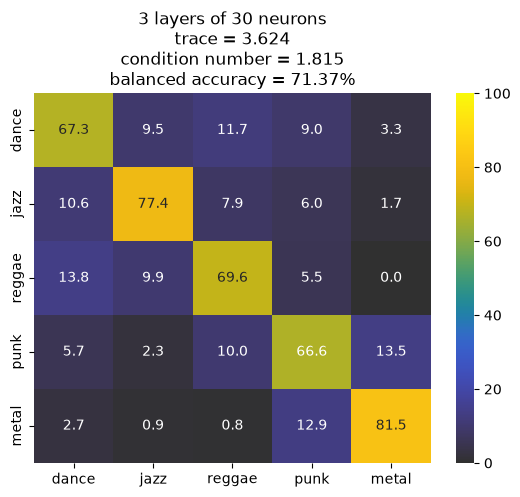

In [246]:
y_pred = model(test[0]).argmax(axis=1).numpy()
y_test = test[1].numpy()

CM = confusion_matrix(y_test,y_pred,normalize="pred")
kwargs = dict(xticklabels=genres,yticklabels=genres,annot=True,fmt='.1f',vmin=0,vmax=100,cmap=cc.cm.gouldian)
report = title(y_test,y_pred,name="3 layers of 30 neurons")
sns.heatmap(100*CM,**kwargs).set(title=report)

# Búsqueda de parámetros

Técnicamente nuestro marco de entrenamiento tiene bastantes hiperparámetros, la sigueinte tabla resume cómo se procederá:

| Hiperparámetro | Búsqueda? | valor/rangos |
| --: | :--: | :-- |
| Número de capas                         |  Y  |  $1 \to 10$
| Número de neuronas por capa             |  Y  | $5 \to 50$                                      
| Batch size                              |  Y  |  $100 \to 700$                     
| Learning rate                           |  Y  | $10^{-4} \to 8 \times 10^{-3}$                        
| Épocas de paciencia                     |  N  |  $15$                              
| Tolerancia para la paciencia            |  N  |  $10^{-2}$                                      
| Métrica para parar el entrenamiento     |  N  | `balanced_accuracy`                                              
| Épocas máximas para el entrenamiento    |  N  |  200                                               
| Parámetro de regularización L2          |  N  | $10^{-4}$

Se realizará el entrenamiento de ~1000 modelos para explorar estos primeros cuatro hiperparámetros, usando los mismos conjuntos de entrenamiento, validación y prueba separados anteriormente.

In [407]:
depths = np.unique(np.logspace(0,1.1,7,dtype=int)).tolist()
depths

[1, 2, 3, 5, 8, 12]

In [408]:
widths = [5, 10, 15, 25, 30, 40, 50] 
batch_sizes = [100, 200, 300, 500, 700] 
learning_rates = [1e-4,5e-4,1e-3,5e-3,8e-3]

grid = ParameterGrid({
    "depth":depths,
    "width":widths,
    "batch_size":batch_sizes,
    "learning_rate":learning_rates
})
len(grid)

1050

Torch usa por defecto todos los cores disponibles. Como se realizará este entrenamiento en un entorno de HPC (el clúster Hypatia de la facultad de ciencias de uniandes), se dividirá esta búsqueda de grilla en diferentes tareas, cada tarea con 4 núcleos de CPU.

In [409]:
internal_grid = ParameterGrid({
    "learning_rate":learning_rates,
    "batch_size":batch_sizes
})
len(internal_grid)

25

In [410]:
external_grid = ParameterGrid({
    "depth":depths,
    "width":widths
})
len(external_grid)

42

Es decir, cada tarea dedicará 4 núcleos a entrenar 25 modelos, y habrá 42 tareas en total.

Se diseñarán las tareas para que midan:

* Accuracy en validación
* Accuracy en prueba
* Época en la que paró el entrenamiento
* Tiempo transcurrido durante el entrenamiento

Cabe recordar que cada modelo se entrena sólo viendo los datos de entrenamiento y se escoge cuándo parar sólo viendo los datos de validación. 

Para cada modelo entrenado se guardarán también sus parámetros, que luego pueden ser reconstruidos de la siguiente manera:

In [411]:
def model_fname_to_grid_indices(model_fname):
    "Return the internal and external grid indices of model according to our naming scheme defined in the grid search"
    clean_name = os.path.splitext(os.path.basename(model_fname))[0]
    return [int(s) for s in clean_name.split("_")[-2:]]

def reconstruct_model(model_fname):
    internal_idx, external_idx = model_fname_to_grid_indices(model_fname)
    config = external_grid[external_idx]
    model = make_mlp(
        input_size = val[0].shape[1],
        output_size = len(np.unique(val[1])),
        hidden_layers = [config["width"]]*config["depth"]
    )
    state = torch.load(model_fname)
    model.load_state_dict(state)
    return model, config

El código de entrenamiento no usa nada diferente a lo ya definido aquí, y está en la carpeta `grid_search`. 

## Resultados

Después de correr la búsqueda de grilla en Hypatia y sincronizar los resultados al github, podemos recuperar los modelos entrenados:

In [412]:
entrenados = sorted(glob("./grid_search/models/*.pt"))

Hay algunos modelos decentes:

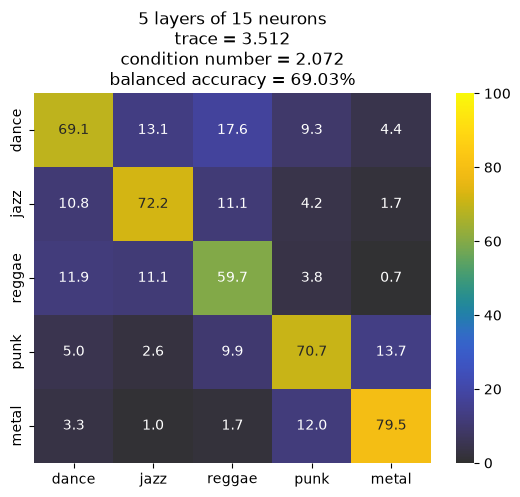

In [422]:
reconstructed_model, config = reconstruct_model(entrenados[100])

y_pred = reconstructed_model(test[0]).argmax(axis=1).numpy()
y_test = test[1].numpy()

CM = confusion_matrix(y_test,y_pred,normalize="pred")
kwargs = dict(xticklabels=genres,yticklabels=genres,annot=True,fmt='.1f',vmin=0,vmax=100,cmap=cc.cm.gouldian)
report = title(y_test,y_pred,name=f"{config["depth"]} layers of {config["width"]} neurons")
sns.heatmap(100*CM,**kwargs).set(title=report);

Otros modelos pésimos:

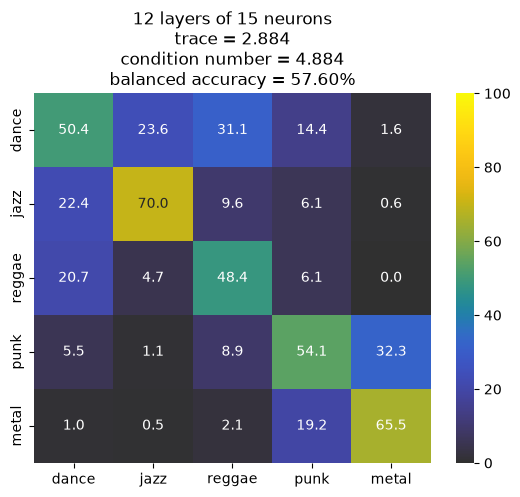

In [414]:
reconstructed_model, config = reconstruct_model(entrenados[31])

y_pred = reconstructed_model(test[0]).argmax(axis=1).numpy()
y_test = test[1].numpy()

CM = confusion_matrix(y_test,y_pred,normalize="pred")
kwargs = dict(xticklabels=genres,yticklabels=genres,annot=True,fmt='.1f',vmin=0,vmax=100,cmap=cc.cm.gouldian)
report = title(y_test,y_pred,name=f"{config["depth"]} layers of {config["width"]} neurons")
sns.heatmap(100*CM,**kwargs).set(title=report);

Como cada tarea escribió en paralelo los resultados en archivos diferentes, para evitar carreras, debemos reunirlos.

Debimos haber guardado más información de los modelos a la hora de entrenar, para evitar esta manera tan incómoda de reconstruir.

In [423]:
csvs = glob("grid_search/stats/*.csv")

In [424]:
col_names = "internal external val_acc test_acc last_epoch train_time".split()

In [425]:
results = pl.concat([pl.scan_csv(fname,with_column_names=lambda c:col_names,has_header=False) for fname in csvs]).collect()

results = results.with_columns(
    depth = pl.struct(["external"]).map_elements(
        lambda row: external_grid[row["external"]]["depth"],
        return_dtype=pl.Int64
    ),
    width = pl.struct(["external"]).map_elements(
        lambda row: external_grid[row["external"]]["width"],
        return_dtype=pl.Int64
    ),
    lr = pl.struct(["internal"]).map_elements(
        lambda row: internal_grid[row["internal"]]["learning_rate"],
        return_dtype=pl.Float64
    ),
    batch_size = pl.struct(["internal"]).map_elements(
        lambda row: internal_grid[row["internal"]]["batch_size"],
        return_dtype=pl.Int64
    ),
).with_columns(
    total_neurons = pl.col("width") * pl.col("depth")
)

In [426]:
best = results.group_by("external").agg(
    pl.all().sort_by("test_acc",descending=True).first()
)

Text(0, 0.5, 'balanced accuracy')

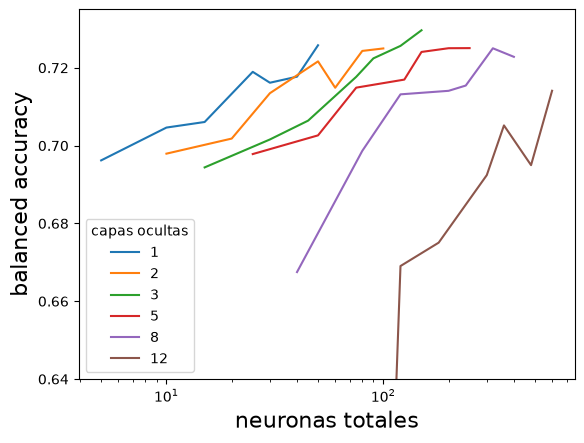

In [430]:
for depth,df in best.sort("depth").group_by("depth",maintain_order=True):
    df = df.sort("total_neurons")
    plt.plot(df["total_neurons"],df["test_acc"],label=depth)
    plt.xscale("log")
plt.ylim(0.64,0.735)
plt.legend(title="capas ocultas")
plt.xlabel("neuronas totales")
plt.ylabel("balanced accuracy")

Parece que, para este problema y con estas arquitecturas cuadradas, las redes con pocas capas son más eficientes que las profundas.

Pero se esperaría que la tendencia tuviera un máximo, parece que no hemos explorado lo suficiente los modelos con pocas capas y muchas neuronas por capa.

Mientras tanto miremos el mejor modelo de esta cohorte:

In [435]:
best.filter(pl.col("test_acc") == best["test_acc"].max())

external,internal,val_acc,test_acc,last_epoch,train_time,depth,width,lr,batch_size,total_neurons
i64,i64,f64,f64,i64,f64,i64,i64,f64,i64,i64
20,13,0.728101,0.72965,30,2.918242,3,50,0.005,300,150


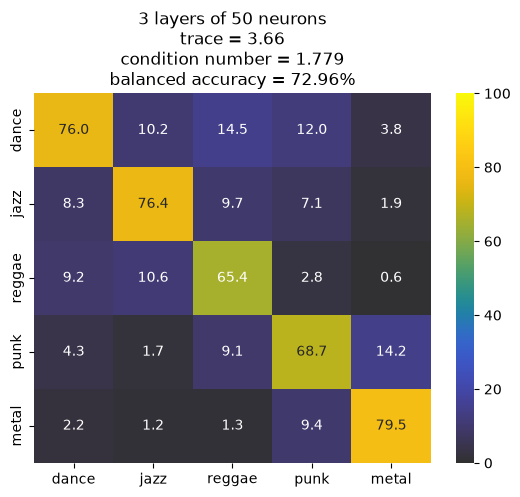

In [437]:
# es internal y luego external
reconstructed_model, config = reconstruct_model("grid_search/models/mlp_13_20.pt") 
y_pred = reconstructed_model(test[0]).argmax(axis=1).numpy()
y_test = test[1].numpy()

CM = confusion_matrix(y_test,y_pred,normalize="pred")
report = title(y_test,y_pred,name=f"{config["depth"]} layers of {config["width"]} neurons")
sns.heatmap(100*CM,**kwargs).set(title=report);

El rendimiento máximo de los modelos parece depender más de la arquitectura y no tanto del learning rate o batch size específicos

Text(0, 0.5, 'test accuracy')

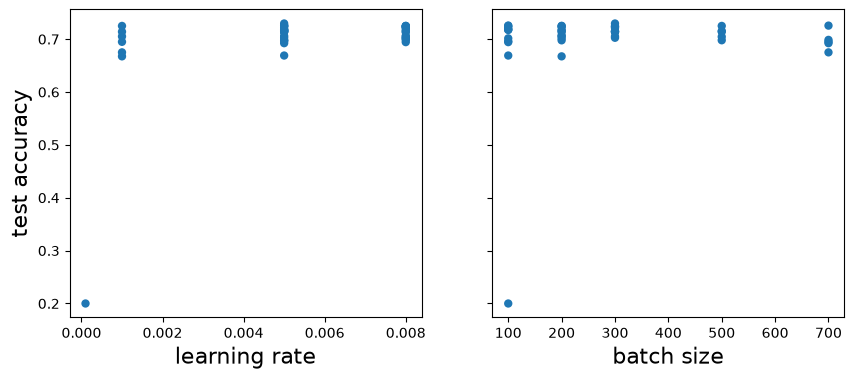

In [448]:
fig,ax = plt.subplots(1,2,figsize=(10,4),sharey=True)
ax[0].scatter(best["lr"],best["test_acc"])
ax[1].scatter(best["batch_size"],best["test_acc"])
ax[0].set_xlabel("learning rate")
ax[1].set_xlabel("batch size")
ax[0].set_ylabel("test accuracy")

# Otra búsqueda, más amplia

Buscaremos capas con muchas más neuronas, pero no gastaremos tiempo en entrenar modelos muy profundos con muchas neuronas.

Limitaremos los batch sizes y learning rates a los más cercanos a los que se sabe que funcionan.

Entrenamos las redes más pesadas primero (por eso el `[::-1]`) para aprovechar mejor el scheduler dinámico de SLURM.

In [449]:
depths = [1, 2, 3, 5, 6, 8][::-1]
widths = [10,20,30,40, 50, 60, 80, 100, 150, 200, 250, 300, 350, 400, 500, 750, 900, 1000][::-1]
external_grid = ParameterGrid({
    "depth":depths,
    "width":widths,
})

batch_sizes = [80, 100, 150, 200, 300]
learning_rates = [3e-3,5e-3,8e-3]
internal_grid = ParameterGrid({
    "learning_rate":learning_rates,
    "batch_size":batch_sizes
})

Sólo entrenaremos las redes con menos de 1051 neuronas.

In [450]:
mult = np.array(depths)[:,None] * np.array(widths)[None,:] * 1.0
mult[mult>1050] = np.nan
mult

array([[  nan,   nan,   nan,   nan,   nan,   nan,   nan,   nan,   nan,   nan,  800.,  640.,  480.,  400.,  320.,  240.,  160.,   80.],
       [  nan,   nan,   nan,   nan,   nan,   nan,   nan,   nan,   nan,  900.,  600.,  480.,  360.,  300.,  240.,  180.,  120.,   60.],
       [  nan,   nan,   nan,   nan,   nan,   nan,   nan,   nan, 1000.,  750.,  500.,  400.,  300.,  250.,  200.,  150.,  100.,   50.],
       [  nan,   nan,   nan,   nan,   nan, 1050.,  900.,  750.,  600.,  450.,  300.,  240.,  180.,  150.,  120.,   90.,   60.,   30.],
       [  nan,   nan,   nan, 1000.,  800.,  700.,  600.,  500.,  400.,  300.,  200.,  160.,  120.,  100.,   80.,   60.,   40.,   20.],
       [1000.,  900.,  750.,  500.,  400.,  350.,  300.,  250.,  200.,  150.,  100.,   80.,   60.,   50.,   40.,   30.,   20.,   10.]])

Serán 108 tareas cada una con 15 entrenamientos.

In [451]:
len(external_grid)

108

In [452]:
len(internal_grid)

15

Pero sólo se esperan ~1100 modelos

In [453]:
(~np.isnan(mult)).sum() * len(internal_grid)

1095

El código de entrenamiento no usa nada diferente a lo ya definido aquí, y está en la carpeta `grid_search_full`. Se modificaron un par de cosas respecto a la anterior búsqueda, principalmente para incluir más métricas y facilidad de importe de resultados.

In [454]:
csvs = glob("grid_search_full/stats/*.csv")
results = (
    pl.concat([df for fname in csvs if (df:=pl.read_csv(fname)).shape[0]])
    .with_columns(total_neurons = pl.col("depth") * pl.col("width"))
)
best = results.group_by("external_idx").agg(pl.all().sort_by("test_acc",descending=True).first())

Text(0, 0.5, 'balanced accuracy')

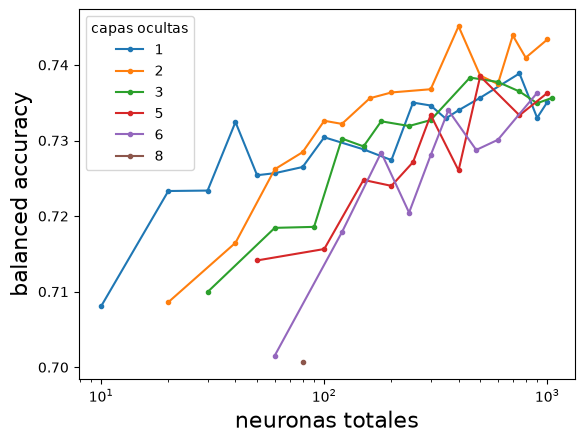

In [455]:
for depth,df in best.sort("depth").group_by("depth",maintain_order=True):
    df = df.filter(pl.col("test_acc")>0.5).sort("total_neurons")
    plt.plot(df["total_neurons"],df["test_acc"],".-",label=depth)
plt.xscale("log")
plt.legend(title="capas ocultas")
plt.xlabel("neuronas totales")
plt.ylabel("balanced accuracy")

Esta vez los modelos de dos capas parecen más promisorios. Examinemos el mejor modelo de esta cohorte:

In [456]:
best.filter(pl.col("test_acc") == best["test_acc"].max())

external_idx,internal_idx,val_acc,test_acc,last_epoch,training_time,depth,width,lr,bs,total_neurons
i64,i64,f64,f64,i64,f64,i64,i64,f64,i64,i64
80,1,0.733664,0.745119,23,6.891406,2,200,0.005,80,400


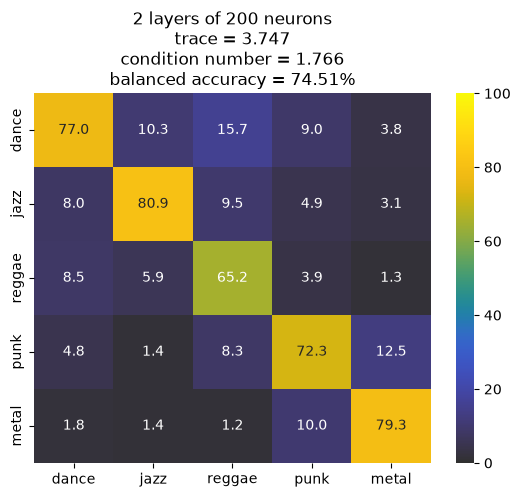

In [457]:
reconstructed_model, config = reconstruct_model("grid_search_full/models/mlp_1_80.pt")
y_pred = reconstructed_model(test[0]).argmax(axis=1).numpy()
y_test = test[1].numpy()

CM = confusion_matrix(y_test,y_pred,normalize="pred")
kwargs = dict(xticklabels=genres,yticklabels=genres,annot=True,fmt='.1f',vmin=0,vmax=100,cmap=cc.cm.gouldian)
report = title(y_test,y_pred,name=f"{config["depth"]} layers of {config["width"]} neurons")
sns.heatmap(100*CM,**kwargs).set(title=report);

Este es el mejor modelo hasta ahora. Lástima que lo mismo se puede lograr con un entrenamiento básico de gradient boosting.

In [494]:
from sklearn.ensemble import HistGradientBoostingClassifier

In [515]:
# esta clase hace la validación adentro, por eso se le mete train+val
boost_model = HistGradientBoostingClassifier(
    max_leaf_nodes=100,
    scoring='balanced_accuracy',
    validation_fraction=0.2/0.6,
    n_iter_no_change=15,
    tol=1e-4
).fit(
    X=np.concat([train[0],val[0]]),
    y=np.concat([train[1],val[1]]),
)

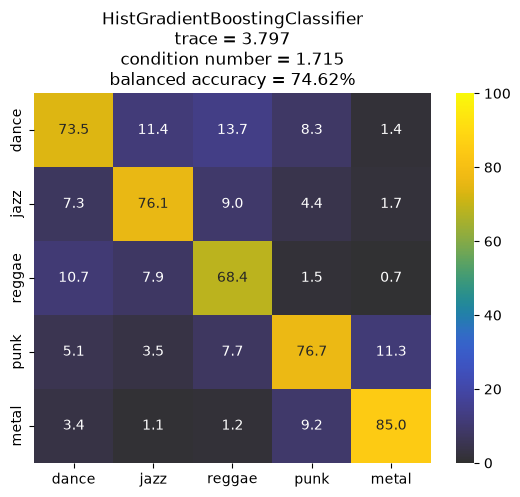

In [516]:
y_pred = boost_model.predict(test[0])
y_test = test[1].numpy()

CM = confusion_matrix(y_test,y_pred,normalize="pred")
report = title(y_test,y_pred,name="HistGradientBoostingClassifier")
sns.heatmap(100*CM,**kwargs).set(title=report);

Pero bueno. Así es la vida. 

Analizando un poco más los resultados, teníamos curiosidad si el accuracy de validación era buen indicativo del accuracy de prueba, y parece ser que sí:

Text(0, 0.5, 'Test accuracy')

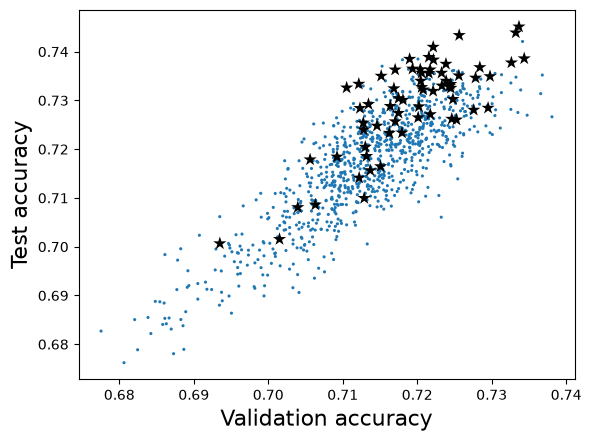

In [550]:
plt.scatter(results["val_acc"],results["test_acc"],s=5)
plt.scatter(best["val_acc"],best["test_acc"],s=100,marker="*",c='k',zorder=10)
plt.xlabel("Validation accuracy")
plt.ylabel("Test accuracy")

Tamibén, puede que seleccionar los modelos por mejor train accuracy sea injusto, pues las medidas de orden (máximo en este caso) suelen tener bastante ruido.

Para eso también mostramos el test accuracy promedio de cada arquitectura (es decir, a lo largo de la malla de learning rate y batch size), y las redes con dos capas ocultas siguen dominando:

Text(0, 0.5, 'mean balanced accuracy')

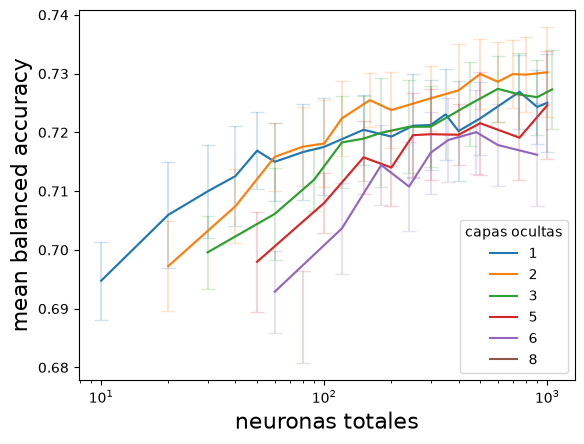

In [551]:
for i,d in enumerate(np.unique(results["depth"])):
    df = results.filter(pl.col("depth")==d).group_by("total_neurons").agg(
        pl.col("test_acc").mean(),
        pl.col("test_acc").std().alias("std")
    ).sort("total_neurons")
    plt.plot(df["total_neurons"],df["test_acc"],label=d,color=f"C{i}")
    plt.errorbar(df["total_neurons"],df["test_acc"],df["std"],capsize=5,alpha=0.2,color=f"C{i}")
plt.xscale("log")
plt.legend(title="capas ocultas")
plt.xlabel("neuronas totales")
plt.ylabel("mean balanced accuracy")

Una muestra del ruido de la gráfica presentada antes:

Text(0, 0.5, 'balanced accuracy')

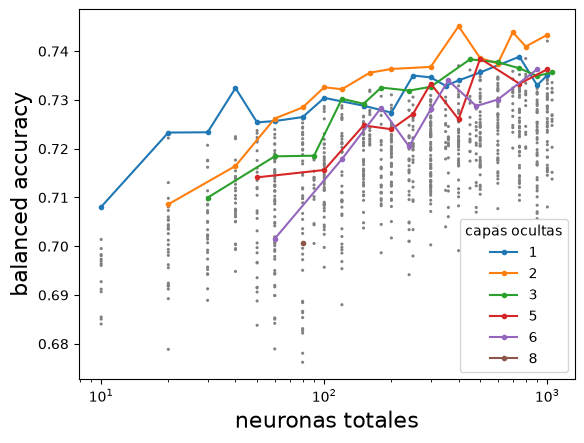

In [553]:
plt.scatter(results["total_neurons"],results["test_acc"],s=5,c="gray")

for depth,df in best.sort("depth").group_by("depth",maintain_order=True):
    df = df.filter(pl.col("test_acc")>0.5).sort("total_neurons")
    plt.plot(df["total_neurons"],df["test_acc"],".-",label=depth)
plt.xscale("log")
plt.legend(title="capas ocultas")
plt.xlabel("neuronas totales")
plt.ylabel("balanced accuracy")

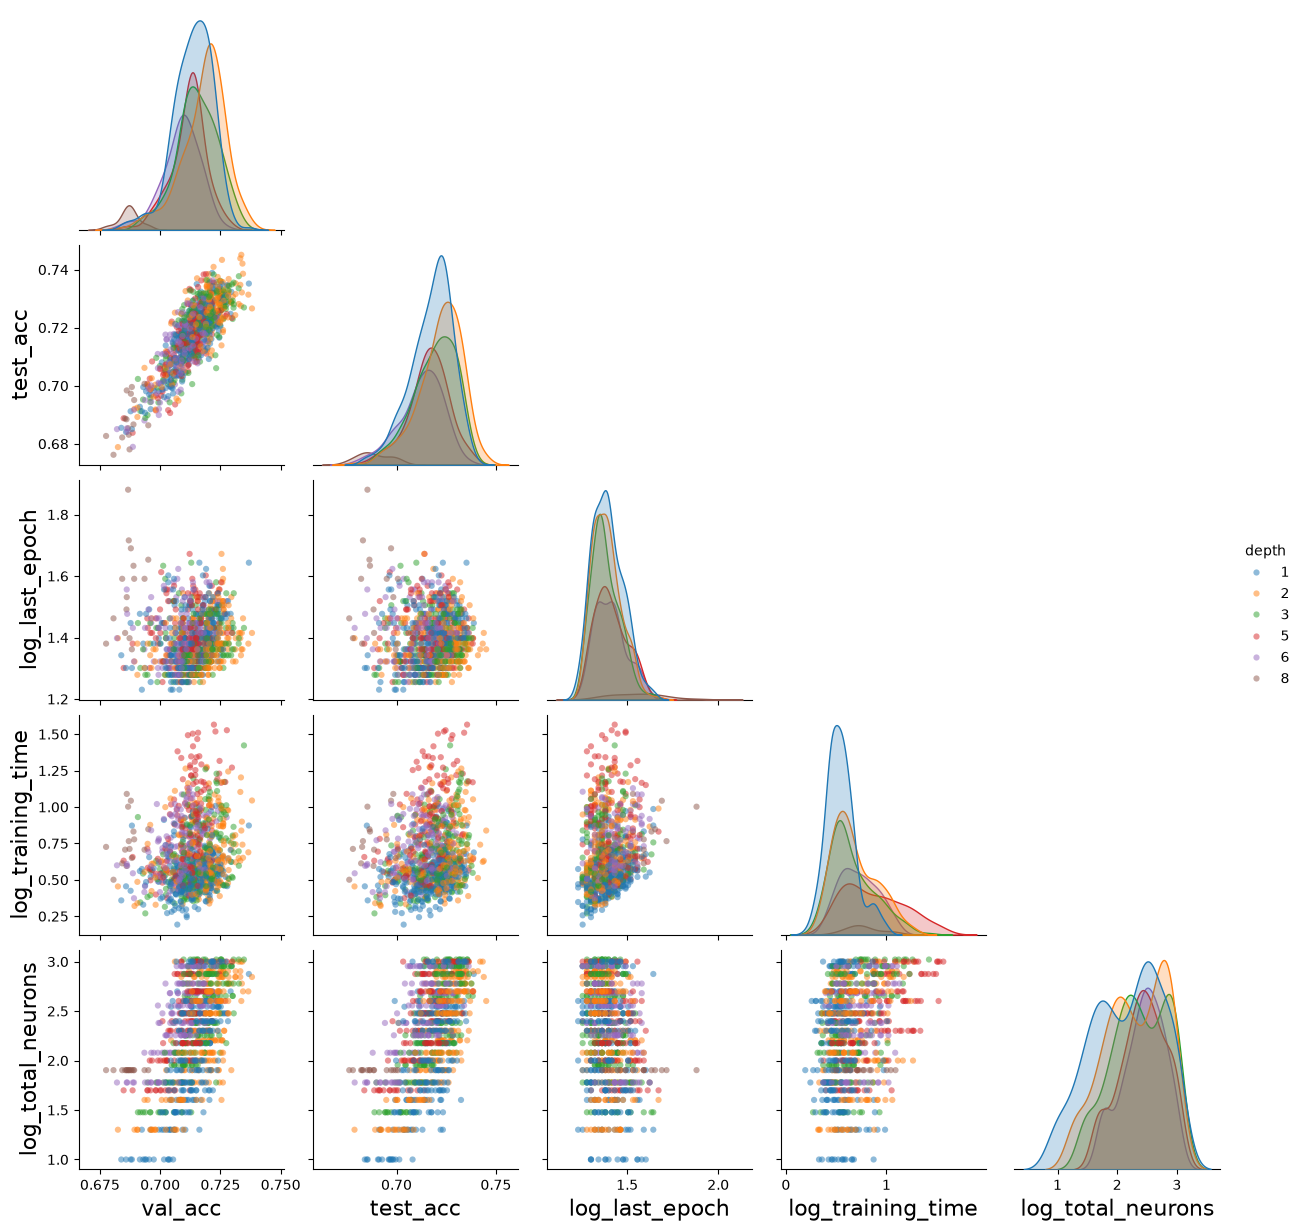

In [563]:
sns.pairplot(
    results.drop("internal_idx","external_idx","width","lr","bs")
    .with_columns(
        log_last_epoch=np.log10(pl.col("last_epoch")),
        log_training_time=np.log10(pl.col("training_time")),
        log_total_neurons=np.log10(pl.col("total_neurons")),
    ).drop("last_epoch","training_time","total_neurons")
    .to_pandas(),
    hue="depth",plot_kws=dict(ec="none",alpha=0.5,s=20),palette="tab10",
    corner=True
)